# 03 – Natural Language Understanding (NLU) Evaluation

In diesem Notebook werden drei NLU-Bausteine für die **Multilingual Voice-NLU Pipeline** anhand der deutschen und englischen Whisper-Transkripte evaluiert:

1. **Named Entity Recognition (NER)** mit **spaCy** (`de_core_news_sm` & `en_core_web_sm`)
2. **Zero-Shot Intent Recognition** mit **XLM-RoBERTa** (`joeddav/xlm-roberta-large-xnli`)
3. **Sentimentanalyse** mit **VADER** (Evaluation der Mehrsprachigkeit)

**Ziel:** Auswahl geeigneter Modelle, die sowohl deutsche als auch englische Spracheingaben zuverlässig ohne eigenes Nachtraining verarbeiten können.

In [6]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import spacy
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from transformers import pipeline

# Referenztexte und Standard-Intents aus data/reference_texts.json laden
ref_path = Path("../data/reference_texts.json")
with ref_path.open("r", encoding="utf-8") as f:
    ref_data = json.load(f)

german_text = ref_data["texts"]["de"]["text"]
english_text = ref_data["texts"]["en"]["text"]
candidate_labels = ref_data["default_intent_labels"]

print("Referenztexte erfolgreich geladen.")
print(f"Länge DE: {len(german_text)} Zeichen | Länge EN: {len(english_text)} Zeichen")
print(f"Kandidaten-Intents ({len(candidate_labels)}): {candidate_labels}")

Referenztexte erfolgreich geladen.
Länge DE: 700 Zeichen | Länge EN: 728 Zeichen
Kandidaten-Intents (9): ['greeting', 'presentation', 'report', 'system failure', 'question', 'reassurance', 'reaction', 'context', 'reflection']


---
## 1. Named Entity Recognition (NER) mit spaCy

Mithilfe vortrainierter spaCy-Sprachmodelle werden strukturierte Entitäten (Personen, Organisationen, Orte, Datums- und Zeitangaben, Zahlen, Prozentwerte und Geldbeträge) aus den transkribierten Texten extrahiert:
- `de_core_news_sm` für Deutsch
- `en_core_web_sm` für Englisch

In [3]:
nlp_de = spacy.load("de_core_news_sm")
nlp_en = spacy.load("en_core_web_sm")

doc_de = nlp_de(german_text)
doc_en = nlp_en(english_text)

def entities_to_df(doc, lang_label):
    rows = [
        {
            "Sprache": lang_label,
            "Entität": ent.text,
            "Label": ent.label_,
            "Beschreibung": spacy.explain(ent.label_) or "Keine Beschreibung"
        }
        for ent in doc.ents
    ]
    return pd.DataFrame(rows)

df_ner_de = entities_to_df(doc_de, "DE")
df_ner_en = entities_to_df(doc_en, "EN")

print("=== Erkannte Entitäten (Deutsch) ===")
display(df_ner_de)

print("=== Erkannte Entitäten (Englisch) ===")
display(df_ner_en)

=== Erkannte Entitäten (Deutsch) ===


,Sprache,Entität,Label,Beschreibung
0,DE,Anna Schneider,PER,Named person or family.
1,DE,Forschungszentrums,ORG,"Companies, agencies, institutions, etc."
2,DE,KI-Studie,ORG,"Companies, agencies, institutions, etc."
3,DE,jemand panisch,PER,Named person or family.
4,DE,Anna,PER,Named person or family.


=== Erkannte Entitäten (Englisch) ===


,Sprache,Entität,Label,Beschreibung
0,EN,"Thursday, March 14, 2024",DATE,Absolute or relative dates or periods
1,EN,Emily Carter,PERSON,"People, including fictional"
2,EN,B3,NORP,Nationalities or religious or political groups
3,EN,Today,DATE,Absolute or relative dates or periods
4,EN,AI,GPE,"Countries, cities, states"
5,EN,"1,278",CARDINAL,Numerals that do not fall under another type
6,EN,five,CARDINAL,Numerals that do not fall under another type
7,EN,92.4%,PERCENT,"Percentage, including ""%"""
8,EN,15%,PERCENT,"Percentage, including ""%"""
9,EN,the previous year,DATE,Absolute or relative dates or periods


### Bewertung der NER-Ergebnisse

#### Deutsche Auswertung (`de_core_news_sm`)
| Entität | Label | Bewertung | Kommentar |
| :--- | :--- | :--- | :--- |
| Anna Schneider | `PER` | korrekt | Klarer Personenname, sauber erkannt |
| Forschungszentrums | `ORG` | korrekt | Als Institution sinnvoll klassifiziert |
| KI-Studie | `ORG` | falsch | Zusammengesetztes Substantiv, keine Organisation |
| jemand panisch | `PER` | falsch | Pronomen + Adjektiv als Eigenname fehlklassifiziert |
| Anna | `PER` | korrekt | Personenname korrekt erkannt |

#### Englische Auswertung (`en_core_web_sm`)
| Entität | Label | Bewertung | Kommentar |
| :--- | :--- | :--- | :--- |
| Thursday, March 14, 2024 | `DATE` | korrekt | Exaktes Datum erkannt |
| Emily Carter | `PERSON` | korrekt | Klarer Personenname |
| B3 | `NORP` | falsch | Raumbezeichnung statt Nationalität/Gruppe |
| Today / the previous year | `DATE` | korrekt | Relative Zeitangaben zuverlässig erkannt |
| AI | `GPE` | falsch | Abkürzung als geografischer Ort fehlklassifiziert |
| 1,278 / five | `CARDINAL` | korrekt | Kardinalzahlen präzise erkannt |
| 92.4% / 15% | `PERCENT` | korrekt | Prozentangaben inkl. Einheit erkannt |
| just $950 | `MONEY` | korrekt | Geldbetrag erkannt |

**Erkenntnis:** Das englische Modell erkennt neben Personen und Organisationen auch Zahlen, Prozentwerte, Geldbeträge und Datumsangaben sehr detailliert. Das deutsche Modell deckt Personen und Institutionen zuverlässig ab, hat aber bei Zahlen/Prozenten und zusammengesetzten Substantiven eine geringere Granularität. Beide Modelle sind extrem schnell und liefern zudem eine saubere Satzsegmentierung (`doc.sents`) für die nachfolgende Intent-Klassifikation.

---
## 2. Zero-Shot Intent Recognition mit XLM-RoBERTa

Für die Absichtserkennung wird das multilinguale Modell `joeddav/xlm-roberta-large-xnli` eingesetzt. Durch das Zero-Shot-Verfahren (basierend auf Cross-lingual Natural Language Inference) lassen sich beliebige Intent-Kategorien ohne vorheriges Training auf Deutsch und Englisch anwenden.

In [4]:
classifier = pipeline(
    "zero-shot-classification",
    model="joeddav/xlm-roberta-large-xnli"
)

def classify_sentences(doc, labels, lang_label):
    sentences = [sent.text.strip() for sent in doc.sents if sent.text.strip()]
    outputs = classifier(
        sentences,
        labels,
        hypothesis_template="This sentence is about {}."
    )
    rows = []
    for sent, out in zip(sentences, outputs):
        rows.append({
            "Sprache": lang_label,
            "Satz": sent,
            "Top-Intent": out["labels"][0],
            "Konfidenz": round(float(out["scores"][0]), 3)
        })
    return pd.DataFrame(rows)

df_intent_en = classify_sentences(doc_en, candidate_labels, "EN")
df_intent_de = classify_sentences(doc_de, candidate_labels, "DE")

print("=== Zero-Shot Intent Recognition (Englisch) ===")
display(df_intent_en)

print("=== Zero-Shot Intent Recognition (Deutsch) ===")
display(df_intent_de)

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 876.12it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== Zero-Shot Intent Recognition (Englisch) ===


,Sprache,Satz,Top-Intent,Konfidenz
0,EN,"On Thursday, March 14, 2024, Dr. Emily Carter ...",reflection,0.188
1,EN,"Good morning, everyone, she began warmly.",greeting,0.890
2,EN,"Today, I'm excited to share the latest results...",report,0.677
3,EN,"The data set included 1,278 entries, categoriz...",reflection,0.205
4,EN,"Interestingly, user engagement increased by 15...",reaction,0.296
5,EN,"But then something unexpected happened, the sy...",system failure,0.622
6,EN,"What just happened, someone asked in a panic.",question,0.518
7,EN,Emily remained calm.,context,0.206
8,EN,"Don't worry, we have a backup.",reassurance,0.923
9,EN,"Later, in an interview, she remarked, sometime...",reflection,0.577


=== Zero-Shot Intent Recognition (Deutsch) ===


,Sprache,Satz,Top-Intent,Konfidenz
0,DE,"Am Dienstag dem 12. März 2024, traf Dr. Anna S...",context,0.182
1,DE,"Guten Morgen, meine Damen und Herren, begann s...",greeting,0.926
2,DE,"Ich freue mich, ihnen heute die Neuesten Ergeb...",presentation,0.647
3,DE,"Die Analyse umfasste 1278 Datensätze, verteilt...",report,0.248
4,DE,Besonders interessant war der Anstieg der Nutz...,reaction,0.226
5,DE,"Doch dann kam eine überraschende Wendung, der ...",reaction,0.527
6,DE,"Was ist passiert, rief jemand panisch.",reaction,0.528
7,DE,Anna blieb ruhig.,context,0.188
8,DE,"Keine Sorge, wir haben ein Back-up-System.",reassurance,0.890


### Bewertung der Zero-Shot Intent Recognition

- **Stärken:** Eindeutige Sprechakte wie `greeting` (*„Good morning, everyone“* / *„Guten Morgen, meine Damen und Herren“*), `system failure` (*„the system crashed“* / *„der server viel plötzlich aus“*), `question` und `reassurance` (*„Don't worry, we have a backup“*) werden sprachübergreifend sehr präzise erkannt.
- **Schwächen:** Abstrakte Kategorien wie `report`, `presentation` und `reflection` können sich kontextuell überlappen. Bei langen Schachtelsätzen sinkt die Trennschärfe.
- **Eignung:** Ideal für mehrsprachige Voice-Pipelines, da neue Intent-Labels zur Laufzeit übergeben werden können.

---
## 3. Sentimentanalyse mit VADER (Sprachvergleich EN vs. DE)

Abschließend wurde geprüft, ob sich das regelbasierte Sentiment-Tool **VADER** (`nltk.sentiment.vader`) als ergänzende Stimmungserkennung in der Pipeline eignet. Dazu werden englische Beispielsätze direkten deutschen Übersetzungen gegenübergestellt.

,Sprache,Text,Klassifikation,Negativ,Neutral,Positiv,Compound
0,EN,I love this product! It's absolutely amazing.,positiv,0.000,0.318,0.682,0.8620
1,EN,"This is an average experience, nothing special.",neutral,0.273,0.727,0.000,-0.3089
2,EN,I hate this. It was a waste of money and time.,negativ,0.481,0.519,0.000,-0.7579
3,DE,Ich liebe dieses Produkt! Es ist absolut großa...,neutral,0.000,1.000,0.000,0.0000
4,DE,"Das ist eine durchschnittliche Erfahrung, nich...",neutral,0.000,1.000,0.000,0.0000
5,DE,Ich hasse das. Es war reine Geld- und Zeitvers...,negativ,0.328,0.672,0.000,-0.5994


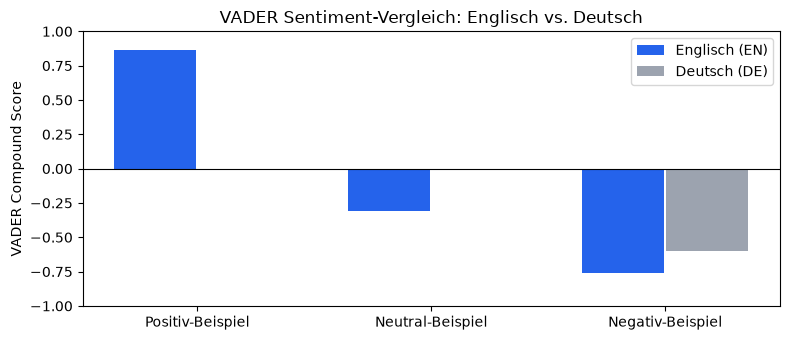

In [5]:
nltk.download("vader_lexicon", quiet=True)
sia = SentimentIntensityAnalyzer()

sample_pairs = [
    ("EN", "I love this product! It's absolutely amazing."),
    ("EN", "This is an average experience, nothing special."),
    ("EN", "I hate this. It was a waste of money and time."),
    ("DE", "Ich liebe dieses Produkt! Es ist absolut großartig."),
    ("DE", "Das ist eine durchschnittliche Erfahrung, nichts Besonderes."),
    ("DE", "Ich hasse das. Es war reine Geld- und Zeitverschwendung."),
]

def classify_vader(text):
    scores = sia.polarity_scores(text)
    compound = scores["compound"]
    if compound >= 0.5:
        label = "positiv"
    elif compound <= -0.5:
        label = "negativ"
    else:
        label = "neutral"
    return label, scores

vader_rows = []
for lang, sentence in sample_pairs:
    label, scores = classify_vader(sentence)
    vader_rows.append({
        "Sprache": lang,
        "Text": sentence,
        "Klassifikation": label,
        "Negativ": scores["neg"],
        "Neutral": scores["neu"],
        "Positiv": scores["pos"],
        "Compound": scores["compound"]
    })

df_vader = pd.DataFrame(vader_rows)
display(df_vader)

# Visualisierung der Compound-Scores: Englisch vs. Deutsch
fig, ax = plt.subplots(figsize=(8, 3.5))
x_labels = ["Positiv-Beispiel", "Neutral-Beispiel", "Negativ-Beispiel"]
en_scores = df_vader[df_vader["Sprache"] == "EN"]["Compound"].tolist()
de_scores = df_vader[df_vader["Sprache"] == "DE"]["Compound"].tolist()

x = range(len(x_labels))
ax.bar([i - 0.18 for i in x], en_scores, width=0.35, label="Englisch (EN)", color="#2563eb")
ax.bar([i + 0.18 for i in x], de_scores, width=0.35, label="Deutsch (DE)", color="#9ca3af")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels(x_labels)
ax.set_ylim(-1.0, 1.0)
ax.set_ylabel("VADER Compound Score")
ax.set_title("VADER Sentiment-Vergleich: Englisch vs. Deutsch")
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. Gesamtfazit für die produktive Pipeline (`src/`)

| Evaluierte Komponente | Mehrsprachigkeit (DE & EN) | Entscheidung für `multilingual-voice-nlu-pipeline` |
| :--- | :--- | :--- |
| **spaCy NER** (`de_core_news_sm`, `en_core_web_sm`) | Ja (über sprachspezifische Pipelines) | **Übernommen (`src/nlu_ner.py`)** – schnelle Entitätenerkennung und Satztrennung. |
| **XLM-RoBERTa** (`joeddav/xlm-roberta-large-xnli`) | Ja (nativ multilingual) | **Übernommen (`src/nlu_intent.py`)** – flexible Zero-Shot-Intenterkennung in beiden Sprachen. |
| **VADER Sentiment** (`nltk`) | Nein (rein englisches Lexikon) | **Nicht übernommen** – liefert auf deutschen Sätzen durchgängig `compound = 0.0` (neutral). |